In [2]:
pip install -q torch torchvision matplotlib scikit-learn gradio


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import torch, random, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from clearml import Task, Logger

task = Task.init(project_name="TP1-MLOps-0-Vision", task_name="Task_ALL_In_One")
logger = Logger.current_logger()

seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

raw_transform = transforms.Compose([transforms.ToTensor()])
train_raw = datasets.CIFAR10(root="./data", train=True,  download=True, transform=raw_transform)
test_raw  = datasets.CIFAR10(root="./data", train=False, download=True, transform=raw_transform)
classes = train_raw.classes

from collections import Counter
cnt = Counter([y for _,y in train_raw])
logger.report_text(f"Class distribution: {cnt}")

fig, axes = plt.subplots(2,5, figsize=(10,4))
for ax in axes.ravel():
    img, y = train_raw[random.randrange(len(train_raw))]
    ax.imshow(np.transpose(img.numpy(), (1,2,0)))
    ax.set_title(classes[y]); ax.axis("off")
logger.report_matplotlib_figure(title="sample_images", series="raw", figure=fig, iteration=0); plt.close(fig)

ClearML Task: created new task id=e886a4dcd3e04207bab60f5b78260f29
2026-10-11 09:48:56,172 - clearml.Task - INFO - No repository found, storing script code instead
ClearML results page: https://app.clear.ml/projects/17f37bac09cf48cfb70be0581bdafd91/tasks/e886a4dcd3e04207bab60f5b78260f29/output/log
2026-10-11 09:48:56,797 - clearml.resource_monitor - WARNING - Could not fetch GPU stats: NVML Shared Library Not Found
Class distribution: Counter({6: 5000, 9: 5000, 4: 5000, 1: 5000, 2: 5000, 7: 5000, 8: 5000, 3: 5000, 5: 5000, 0: 5000})


ClearML Monitor: GPU monitoring failed getting GPU reading, switching off GPU monitoring
ClearML Monitor: Could not detect iteration reporting, falling back to iterations as seconds-from-start


In [7]:
from torch.utils.data import DataLoader

config = {
    "img_size": 32,
    "batch_size": 128,
    "num_workers": 2,
    "lr": 1e-3,
    "epochs": 5,
    "weight_decay": 1e-4,
}
task.connect(config)   # visibles/modifiables dans l'UI ClearML

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.CIFAR10("./data", train=True,  transform=train_tf)
test_ds  = datasets.CIFAR10("./data", train=False, transform=test_tf)

train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True,  num_workers=config["num_workers"])
test_loader  = DataLoader(test_ds,  batch_size=config["batch_size"], shuffle=False, num_workers=config["num_workers"])

print("Préparation OK.")

Préparation OK.


In [9]:
import torch.nn as nn, torch.optim as optim, os
from torchvision.models import resnet18
from clearml import Task, Logger

# 👉 modif 1 : "mps" = le GPU des Mac Apple (le TP original ne prévoit que "cuda" = GPU NVIDIA)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Calcul sur :", device)

model = resnet18(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])

# Dossier local pour les checkpoints
os.makedirs("checkpoints", exist_ok=True)

# Reprise du dernier checkpoint si disponible
latest_ckpt = sorted([f for f in os.listdir("checkpoints") if f.endswith(".pt")])
if latest_ckpt:
    last_path = os.path.join("checkpoints", latest_ckpt[-1])
    model.load_state_dict(torch.load(last_path, map_location=device))
    print(f"Reprise du dernier checkpoint : {last_path}")

def train_one_epoch(epoch):
    model.train(); running_loss, correct, total = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * x.size(0)
        pred = out.argmax(1)
        correct += (pred == y).sum().item(); total += y.size(0)
    train_loss = running_loss / total; train_acc = correct / total
    Logger.current_logger().report_scalar("loss", "train", train_loss, epoch)
    Logger.current_logger().report_scalar("accuracy", "train", train_acc, epoch)
    return train_loss, train_acc

@torch.no_grad()
def evaluate(epoch, loader=test_loader, split="val"):
    model.eval(); running_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x); loss = criterion(out, y)
        running_loss += loss.item() * x.size(0)
        pred = out.argmax(1); correct += (pred == y).sum().item(); total += y.size(0)
    loss = running_loss / total; acc = correct / total
    Logger.current_logger().report_scalar("loss", split, loss, epoch)
    Logger.current_logger().report_scalar("accuracy", split, acc, epoch)
    return loss, acc

for ep in range(config["epochs"]):
    print(f"\n----- Époque {ep+1}/{config['epochs']} -----")
    tl, ta = train_one_epoch(ep)
    vl, va = evaluate(ep)
    # 👉 modif 2 : on affiche les chiffres pour suivre l'apprentissage
    print(f"train : loss {tl:.3f} | accuracy {ta:.1%}    val : loss {vl:.3f} | accuracy {va:.1%}")

    ckpt_path = f"checkpoints/epoch_{ep:03d}.pt"
    torch.save(model.state_dict(), ckpt_path)
    task.upload_artifact(name=f"checkpoint_epoch_{ep:03d}", artifact_object=ckpt_path)
    Logger.current_logger().report_text(f"Checkpoint ClearML uploadé : {ckpt_path}")

print("Entraînement terminé.")

Calcul sur : mps

----- Époque 1/5 -----
train : loss 1.541 | accuracy 44.1%    val : loss 1.343 | accuracy 52.3%
Checkpoint ClearML uploadé : checkpoints/epoch_000.pt

----- Époque 2/5 -----
2026-10-11 10:26:10,165 - clearml.storage - INFO - Uploading: 42.73MB from /Users/Amine/Desktop/EIGSI/MLops_TP0/checkpoints/epoch_000.pt


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.43MB/s]: 


train : loss 1.185 | accuracy 57.6%    val : loss 1.053 | accuracy 62.8%
Checkpoint ClearML uploadé : checkpoints/epoch_001.pt

----- Époque 3/5 -----
2026-10-11 10:26:57,257 - clearml.storage - INFO - Uploading: 42.73MB from /Users/Amine/Desktop/EIGSI/MLops_TP0/checkpoints/epoch_001.pt


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00,  9.71MB/s]: 


train : loss 1.019 | accuracy 63.8%    val : loss 0.905 | accuracy 68.5%
Checkpoint ClearML uploadé : checkpoints/epoch_002.pt

----- Époque 4/5 -----
2026-10-11 10:27:38,786 - clearml.storage - INFO - Uploading: 42.73MB from /Users/Amine/Desktop/EIGSI/MLops_TP0/checkpoints/epoch_002.pt


...

train : loss 0.921 | accuracy 67.7%    val : loss 0.906 | accuracy 68.5%
Checkpoint ClearML uploadé : checkpoints/epoch_003.pt

----- Époque 5/5 -----
2026-10-11 10:28:25,576 - clearml.storage - INFO - Uploading: 42.73MB from /Users/Amine/Desktop/EIGSI/MLops_TP0/checkpoints/epoch_003.pt


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.30MB/s]: 


train : loss 0.851 | accuracy 70.1%    val : loss 0.884 | accuracy 69.5%
Checkpoint ClearML uploadé : checkpoints/epoch_004.pt
Entraînement terminé.


2026-10-11 10:29:11,905 - clearml.storage - INFO - Uploading: 42.73MB from /Users/Amine/Desktop/EIGSI/MLops_TP0/checkpoints/epoch_004.pt


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.43MB/s]: 


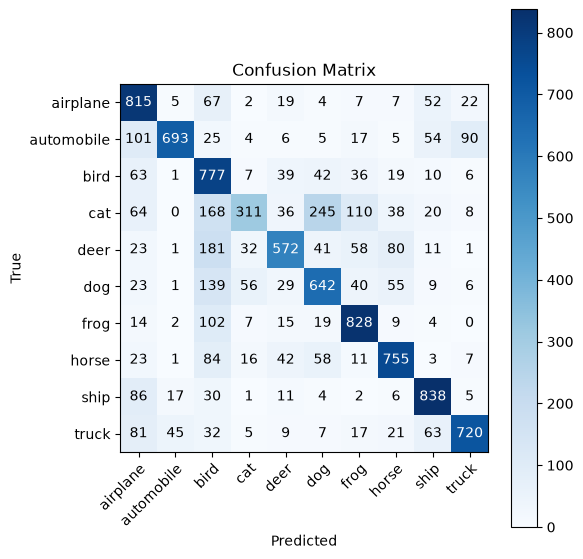

Validation OK.


In [10]:
import itertools
from sklearn.metrics import confusion_matrix
import numpy as np

@torch.no_grad()
def eval_confusion():
    model.eval(); all_y, all_p = [], []
    for x,y in test_loader:
        x = x.to(device)
        p = model(x).argmax(1).cpu().numpy()
        all_p.extend(p); all_y.extend(y.numpy())
    cm = confusion_matrix(all_y, all_p, labels=list(range(10)))
    return cm

cm = eval_confusion()

fig, ax = plt.subplots(figsize=(6,6))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
tick_marks = np.arange(len(classes))
ax.set(xticks=tick_marks, yticks=tick_marks, xticklabels=classes, yticklabels=classes,
       ylabel='True', xlabel='Predicted', title="Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    ax.text(j, i, format(cm[i, j], 'd'), ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2. else "black")
plt.tight_layout()
logger.report_matplotlib_figure(title="confusion_matrix", series="val", figure=fig, iteration=0)
plt.show()   # 👉 ajout : affiche aussi la figure dans le notebook
plt.close(fig)
print("Validation OK.")

In [11]:
from clearml import OutputModel

# 👉 correction : on crée d'abord le fichier du meilleur modèle.
# Ici le meilleur est le dernier (époque 5 : 69,5 % en val)
torch.save(model.state_dict(), "best_resnet18_cifar10.pt")

# 1) On l'attache à l'expérience comme artefact
task.upload_artifact("best_checkpoint", artifact_object="best_resnet18_cifar10.pt")

# 2) On le publie dans le Model Registry
output_model = OutputModel(task=task, name="resnet18_cifar10_tp1")
output_model.update_weights("best_resnet18_cifar10.pt")
output_model.publish()   # verrouille la version

logger.report_text(f"Model published: {output_model.id}")
print("Modèle publié dans le Model Registry ClearML :", output_model.id)

2026-10-11 10:43:23,845 - clearml.storage - INFO - Uploading: 42.73MB from /Users/Amine/Desktop/EIGSI/MLops_TP0/best_resnet18_cifar10.pt


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.45MB/s]: 


2026-10-11 10:43:42,191 - clearml.model - INFO - No output storage destination defined, registering local model best_resnet18_cifar10.pt
Model published: 4b901e3f81c140b6aa9caf4cb43abe1f
Modèle publié dans le Model Registry ClearML : 4b901e3f81c140b6aa9caf4cb43abe1f
